# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Соснило Богдан Тарасович'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 12      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 12, файл lr6_варіант_12.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'      # 'класифікація' / 'регресія' / 'кластеризація' / 'зменшення розмірності'
# чому: бо ми класифікуємо чи буде відтік клієнта(клас "так" або значення 1) або не буде відтік(клас "ні" або значення 0)

METRIC = 'AUC'            # 'точність' / 'AUC' / 'F1' / 'повнота' / 'MAE'
# чому саме ця, а не точність: у нас присутній дизбаланс класів(відтік = 0.249), тому точність не підходить. Обрано AUC, бо воно оцінює здатність моделі сортувати в нашому випадку клієнтів по ймовірності їх відтоку

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'         # напр. 'стратифікована 5-кратна, 4 повтори'
# чому саме така: стратифікація гарантує, що частка відтоку збережеться в кожному фолді

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.249

типи стовпців: {'object': 13, 'float64': 8, 'int64': 5}


In [6]:
# ----- ВАШ КОД: таблиця «стовпець | тип | унікальних | % пропусків | приклад» -----
# Відсортуйте за часткою пропусків спадно і покажіть усі стовпці.
info = []
for c in raw.columns:
    info.append({
        'стовпець': c,
        'тип': raw[c].dtype,
        'унікальних': raw[c].nunique(),
        '% пропусків': (raw[c].isna().mean() * 100).round(1),
        'приклад': raw[c].dropna().iloc[0] if not raw[c].dropna().empty else None
    })

df_info = pd.DataFrame(info).sort_values('% пропусків', ascending=False)

pd.set_option('display.max_rows', None)
display(df_info)
pd.reset_option('display.max_rows') 

,стовпець,тип,унікальних,% пропусків,приклад
23,сума_повернення_депозиту,float64,299,75.1,408.09
22,дата_розірвання,object,254,75.1,2024-12-15
17,середній_час_відповіді_хв,float64,266,32.4,32.1
14,трафік_ГБ,object,956,5.0,51.9
12,щомісячний_платіж,object,1131,4.0,288.66
16,аварій_на_ділянці_за_квартал,float64,6,3.0,1.0
2,стать,object,6,0.0,Ч
3,місто,object,6,0.0,Золочів
0,id_клієнта,object,1200,0.0,K120000
1,вік,float64,63,0.0,35.0


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
print("--- 1. Числова колонка з текстом ---")
for c in raw.select_dtypes(include=['object']):
    if raw[c].str.contains(r'\d', na=False).any() and raw[c].str.contains(r'[а-яА-Яa-zA-Z]', na=False).any():
        print(f"Кандидат: '{c}'")
        display(raw[c].dropna().sample(3, random_state=42))

print("\n--- 2. Число, яке Excel перетворив на дату ---")
for c in raw.columns:
    if pd.api.types.is_datetime64_any_dtype(raw[c]):
        print(f"Кандидат (тип datetime): '{c}'")
        display(raw[c].dropna().sample(3, random_state=42))
    elif raw[c].dtype == 'object' and raw[c].astype(str).str.match(r'^\d{4}-\d{2}-\d{2}').any():
        print(f"Кандидат (текст у форматі дати): '{c}'")
        display(raw[c].dropna().sample(3, random_state=42))

print("\n--- 3. MNAR (пропуски, які не випадкові) ---")
mnar_candidates = df_info[(df_info['% пропусків'] > 10) & (df_info['% пропусків'] < 90)]
display(mnar_candidates[['стовпець', '% пропусків', 'приклад']])

--- 1. Числова колонка з текстом ---
Кандидат: 'id_клієнта'


1178    K121178
865     K120865
101     K120101
Name: id_клієнта, dtype: object

Кандидат: 'філія'


1178      Ф-04 Південь
865       Ф-04 Південь
101     Ф-06 Приміська
Name: філія, dtype: object

Кандидат: 'щомісячний_платіж'


181    306.39
784    334.73
609    351.94
Name: щомісячний_платіж, dtype: object

... (6 outputs left out)

Кандидат (текст у форматі дати): 'дата_розірвання'


1118    2025-10-10
1042    2025-01-19
657     2023-03-17
Name: дата_розірвання, dtype: object


--- 3. MNAR (пропуски, які не випадкові) ---


,стовпець,% пропусків,приклад
23,сума_повернення_депозиту,75.1,408.09
22,дата_розірвання,75.1,2024-12-15
17,середній_час_відповіді_хв,32.4,32.1


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'автоплатіж'
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'
PROBLEM_MNAR           = 'дата_розірвання'    

MNAR_MEANING           = 'пропуски є тільки у тих клієнтів, які не розривали договір з провайдером.'    

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        if pd.isna(v): return np.nan
        if isinstance(v, (datetime.datetime, pd.Timestamp)): return np.nan
        if isinstance(v, (int, float)): return float(v)
        if isinstance(v, str):
            # re.match шукає число ТІЛЬКИ на початку рядка (ігноруючи пробіли)
            match = re.match(r'^\s*([-+]?\d+(?:[.,]\d+)?)', v)
            if match:
                return float(match.group(1).replace(',', '.'))
            else:
                return np.nan
        return np.nan
    return s.map(one)

# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']   

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        
        if c == 'дата_підключення' or c == 'дата_розірвання':
            # pd.to_datetime розпізнає дату, а toordinal() робить із неї число (кількість днів з 1 січня 1 року)
            X[c] = pd.to_datetime(d[c], errors='coerce').apply(
                lambda x: x.toordinal() if pd.notna(x) else np.nan
            )
            log.append({'стовпець': c, 'перетворення': 'число (з дати)'})
            continue
            
        if pd.api.types.is_numeric_dtype(d[c]):
            X[c] = d[c].astype(float)
            log.append({'стовпець': c, 'перетворення': 'float'})
            continue
            
        s_num = to_number(d[c])
        mask = d[c].notna() 
        
        if mask.sum() > 0 and (s_num[mask].notna().sum() / mask.sum()) > 0.8:
            X[c] = s_num
            log.append({'стовпець': c, 'перетворення': 'float (витягнуто з тексту)'})
        else:
            X[c] = d[c].apply(
                lambda x: str(x).lower().strip() if pd.notna(x) else np.nan
            ).astype('category')
            log.append({'стовпець': c, 'перетворення': 'category'})
            
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 8


,стовпець,перетворення
0,вік,float
1,стать,category
2,місто,category
3,філія,category
4,тариф,category
5,тип_підключення,category
6,спосіб_оплати,category
7,автоплатіж,category
8,кількість_послуг,float
9,місяців_обслуговування,float


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    num_cols = X.select_dtypes(include=['float64', 'int64']).columns
    cat_cols = X.select_dtypes(include=['category']).columns
    
    num_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    
    cat_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])
    
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', num_transformer, num_cols),
            ('cat', cat_transformer, cat_cols)
        ], sparse_threshold=0)
    
    return Pipeline(steps=[('prep', preprocessor),
                           ('clf', clf)])

def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.969


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.968 ± 0.013
час      : 1.7 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = 'число AUC близьке до 1.0 означає, що модель майже ідеально розділяє класи, що найімовірніше свідчить про data leakage'
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

число AUC близьке до 1.0 означає, що модель майже ідеально розділяє класи, що найімовірніше свідчить про data leakage


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
            
        is_filled = d[c].notna().astype(int)
        
        n_filled = is_filled.sum()
        n_missing = len(d) - n_filled
        
        if n_filled >= min_group and n_missing >= min_group:
            score = roc_auc_score(y, is_filled)

            if score < 0.5:
                score = 1.0 - score
                
            churn_filled = y[is_filled == 1].mean()
            churn_missing = y[is_filled == 0].mean()
            
            rows.append({
                'ознака': c,
                'заповнено': n_filled,
                'частка_відтоку_де_заповнено': round(churn_filled, 3),
                'частка_відтоку_де_пропуск': round(churn_missing, 3),
                'показник': round(score, 3)
            })
        else:
            rows.append({
                'ознака': c,
                'заповнено': n_filled,
                'частка_відтоку_де_заповнено': None,
                'частка_відтоку_де_пропуск': None,
                'показник': 0.5
            })
            
    return pd.DataFrame(rows).sort_values('показник', ascending=False)

scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,дата_розірвання,299,1.000,0.000,1.000
23,сума_повернення_депозиту,299,1.000,0.000,1.000
17,середній_час_відповіді_хв,811,0.275,0.195,0.547
14,трафік_ГБ,1140,0.247,0.283,0.505
16,аварій_на_ділянці_за_квартал,1164,0.250,0.222,0.502
12,щомісячний_платіж,1152,0.248,0.271,0.502
2,стать,1200,NaN,NaN,0.500
1,вік,1200,NaN,NaN,0.500
0,id_клієнта,1200,NaN,NaN,0.500
8,автоплатіж,1200,NaN,NaN,0.500


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = ['дата_розірвання',
'сума_повернення_депозиту'   
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['дата_розірвання', 'сума_повернення_депозиту']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.968 ± 0.012


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'код_тарифного_плану', 'скоринг_партнера', 'дата_підключення', 'оцінка_ризику_менеджером']


In [18]:
HUMAN_LEAK = ['оцінка_ризику_менеджером'    ## це аналіз ризиків відтоку клієнта менеджером, 

             ]
HUMAN_LEAK_WHY = 'детектор його не спіймау, бо ця колонка не є наслідком відтоку клієнту, а є оцінкою того, наскільки великий шанс, що клієнт розірве контакт, тобто прогноз відтоку'      # чому детектор із 5.1 його не спіймав

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.825 ± 0.030


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

--- 1. Частка відтоку за кожною філією ---


,частка_відтоку,клієнтів
філія,,
Ф-01 Центр,0.413,213
Ф-02 Захід,0.378,193
Ф-03 Схід,0.162,204
Ф-04 Південь,0.159,201
Ф-05 Північ,0.173,197
Ф-06 Приміська,0.203,192



--- 2. Частка відтоку по кварталах дати підключення ---


,частка_відтоку,клієнтів
дата_підключення,,
2023Q1,0.248,129
2023Q2,0.229,140
2023Q3,0.261,161
2023Q4,0.281,171
2024Q1,0.230,152
2024Q2,0.260,154
2024Q3,0.175,137
2024Q4,0.295,156


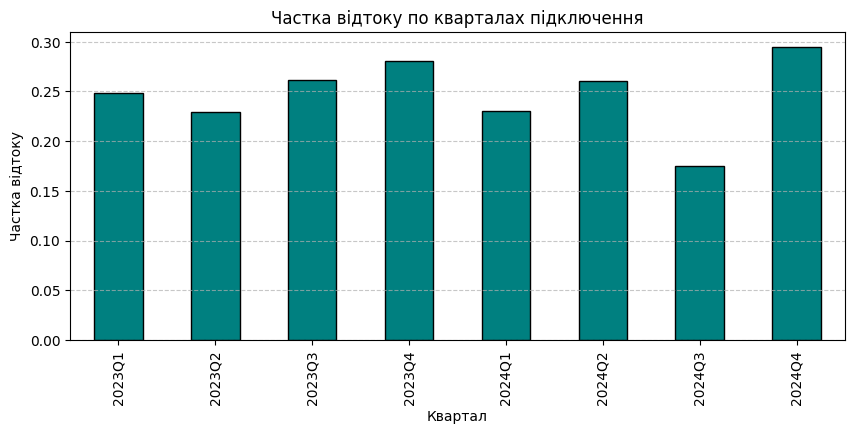

In [19]:
print("--- 1. Частка відтоку за кожною філією ---")
branch_stat = raw.groupby('філія')[TARGET].agg(['mean', 'count']).round(3)
branch_stat.rename(columns={'mean': 'частка_відтоку', 'count': 'клієнтів'}, inplace=True)
display(branch_stat)

print("\n--- 2. Частка відтоку по кварталах дати підключення ---")
dates = pd.to_datetime(raw['дата_підключення'], errors='coerce')

quarters = dates.dt.to_period('Q')

quarter_stat = raw.groupby(quarters)[TARGET].agg(['mean', 'count']).round(3)
quarter_stat.rename(columns={'mean': 'частка_відтоку', 'count': 'клієнтів'}, inplace=True)
display(quarter_stat)

plt.figure(figsize=(10, 4))
quarter_stat['частка_відтоку'].plot(kind='bar', color='teal', edgecolor='black')
plt.title('Частка відтоку по кварталах підключення')
plt.ylabel('Частка відтоку')
plt.xlabel('Квартал')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'філія'        # 'філія' або 'дата_підключення' — що саме ви підозрюєте
assert SUSPECT in ('філія', 'дата_підключення')

# ----- ВАШ КОД: побудуйте бінарну змінну source -----
source = raw['філія'].isin(['Ф-01 Центр', 'Ф-02 Захід']).astype(int)

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')

print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.714
ті самі ознаки передбачають ВІДТІК  : AUC 0.785 ± 0.039


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.968
2. мінус цільовий витік,22,0.968
3. мінус оцінки людини,21,0.825
4. мінус артефакт збору,20,0.785


чесне число: 0.785 ± 0.039


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'викинути'    # 'викинути' / 'залишити' / 'залишити, але звітувати окремо'

DECISION_WHY = 'Оскільки AUC джерела = 0.714 > 0.5, клієнти в різних філіях системно відрізняються за своїми ознаками. Коли ми маємо в ознаках філію, то модель просто вивчає, що при певній філії небезпека зростає, проте ми хочемо знайти глибші залежності. При відсутній філії модель шукає певні інші, глибші залежності, які впливають на результат.'

assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — Оскільки AUC джерела = 0.714 > 0.5, клієнти в різних філіях системно відрізняються за своїми ознаками. Коли ми маємо в ознаках філію, то модель просто вивчає, що при певній філії небезпека зростає, проте ми хочемо знайти глибші залежності. При відсутній філії модель шукає певні інші, глибші залежності, які впливають на результат.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.785,0.039,1.7
одне дерево,0.622,0.035,1.3
випадковий ліс,0.785,0.029,11.4
гістограмний бустинг,0.792,0.024,14.3


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
from scipy import stats

def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    diff = b - a
    
    m = diff.mean()
    
    se = diff.std(ddof=1) / np.sqrt(len(diff))
    
    t_val = stats.t.ppf(0.975, len(diff) - 1)
    
    # Півширина інтервалу
    h = t_val * se
    
    return m, h


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: -0.0002 ± 0.0148   у межах шуму
гістограмний бустинг   проти логістичної: +0.0068 ± 0.0150   у межах шуму


In [25]:
CHOSEN_MODEL = 'логістична регресія'     # назва з MODELS
CHOSEN_WHY = 'Якість (AUC) складних моделей не має значущої переваги над регресією, але регресія навчається в рази швидше.'
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — Якість (AUC) складних моделей не має значущої переваги над регресією, але регресія навчається в рази швидше.


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    

    if 'щомісячний_платіж' in F.columns and 'швидкість_тарифу_Мбіт' in F.columns:
        F['ціна_за_мбіт'] = F['щомісячний_платіж'] / (F['швидкість_тарифу_Мбіт'] + 1)
        
    if 'аварій_на_ділянці_за_квартал' in F.columns:
        F['були_аварії'] = (F['аварій_на_ділянці_за_квартал'] > 0).astype(int)
        

    if 'кількість_звернень_у_підтримку' in F.columns and 'місяців_обслуговування' in F.columns:
        months = F['місяців_обслуговування'].clip(lower=1)
        F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / months

    return F

X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 23


In [27]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.782 ± 0.038
приріст проти базового набору: -0.0027 ± 0.0014   значуще


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
FEATURES_VS_MODEL = 'Оскільки математично залежні ознаки погано впливають на логістичну регресію, почались конфлікти ваг і коеф. AUC зменшився. якби ми обрали іншу модель(випадковий ліс), скоріше всього нові ознаки їм би допомогли. тому порівнюючи, складніша модель дає кращий результат за більше часу, проте легша модель робить це з трохи меншою точністю, проте в десятки разів швидше'
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

Оскільки математично залежні ознаки погано впливають на логістичну регресію, почались конфлікти ваг і коеф. AUC зменшився. якби ми обрали іншу модель(випадковий ліс), скоріше всього нові ознаки їм би допомогли. тому порівнюючи, складніша модель дає кращий результат за більше часу, проте легша модель робить це з трохи меншою точністю, проте в десятки разів швидше


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X = X5        
# з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.800
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

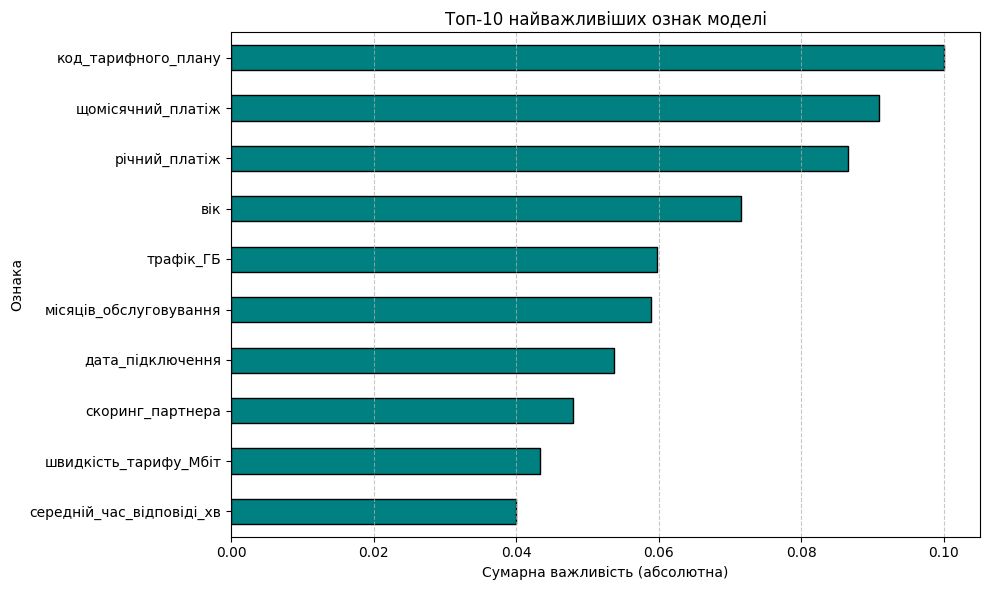

In [30]:

out_names = model.named_steps['prep'].get_feature_names_out()

clf = model.named_steps['clf']

if hasattr(clf, 'feature_importances_'):
    raw_imp = clf.feature_importances_
else:
    raw_imp = np.abs(clf.coef_[0])

imp_dict = {col: 0.0 for col in X4.columns}

for out_name, imp in zip(out_names, raw_imp):
    step, feature = out_name.split('__', 1)
    
    for orig_col in X4.columns:
        if step == 'num' and feature == orig_col:
            imp_dict[orig_col] += imp
            break
        elif step == 'cat' and feature.startswith(orig_col + '_'):
            imp_dict[orig_col] += imp
            break

gini_imp = pd.Series(imp_dict).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
gini_imp.tail(10).plot(kind='barh', color='teal', edgecolor='black')
plt.title('Топ-10 найважливіших ознак моделі')
plt.xlabel('Сумарна важливість (абсолютна)')
plt.ylabel('Ознака')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.035689
трафік_ГБ,0.026444
щомісячний_платіж,0.019519
звернень_на_місяць,0.017562
місяців_обслуговування,0.015895
річний_платіж,0.013693
автоплатіж,0.008755
знижка_відсоток,0.004551
кількість_звернень_у_підтримку,0.003708
дата_підключення,0.003327


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
import pandas as pd

comparison_table = pd.DataFrame({
    'вбудована': gini_imp,
    'перестановочна': perm_imp  
})

comparison_table = comparison_table.sort_values(by='вбудована', ascending=False)

display(comparison_table)

,вбудована,перестановочна
код_тарифного_плану,0.100116,-0.000128
щомісячний_платіж,0.090958,0.019519
річний_платіж,0.086574,0.013693
вік,0.071532,0.035689
трафік_ГБ,0.059798,0.026444
місяців_обслуговування,0.058867,0.015895
дата_підключення,0.053805,0.003327
скоринг_партнера,0.048001,0.001103
швидкість_тарифу_Мбіт,0.043395,-0.000961
середній_час_відповіді_хв,0.040027,0.000691


In [33]:
FAKE_IMPORTANT = 'код_тарифного_плану'        # назва ознаки
FAKE_IMPORTANT_WHY = 'Ознака має багато унікальних значень на розбиття, тому можна було штучно знайти таке значення порогу, при якому неоднорідність стає найменшою, тобто модель просто перенавчається замість того, шоб шукати закономірності.при перестановці ми побачили, що код тарифного плану майже ніяк не впливає на цільове значення'   # чому вбудована важливість її переоцінює
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: код_тарифного_плану


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

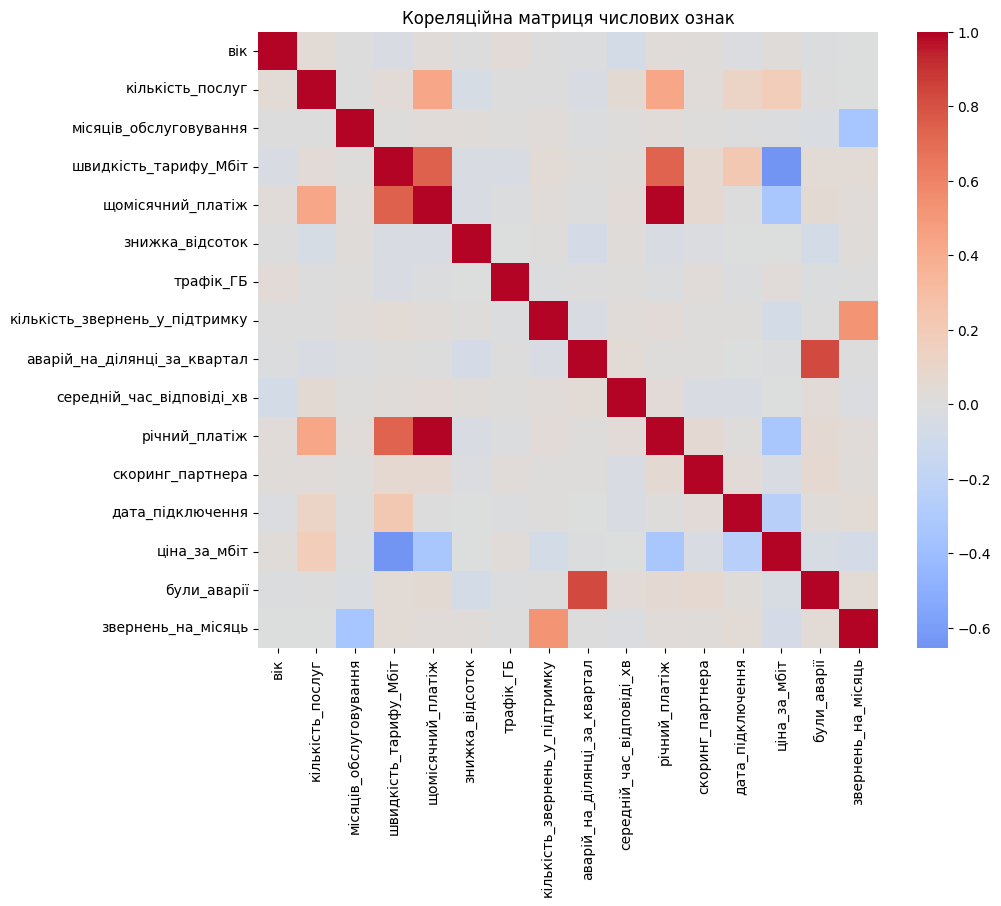

Пари ознак із кореляцією |r| > 0.97:
- щомісячний_платіж та річний_платіж (r = 0.9992)


In [34]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

num_data = FINAL_X.select_dtypes(include=['int64', 'float64'])

corr_matrix = num_data.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, annot=False)
plt.title('Кореляційна матриця числових ознак')
plt.show()

upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

print("Пари ознак із кореляцією |r| > 0.97:")
for col in upper_tri.columns:
    for row in upper_tri.index:
        r_val = upper_tri[col][row]
        if pd.notna(r_val) and abs(r_val) > 0.97:
            print(f"- {row} та {col} (r = {r_val:.4f})")

In [35]:
from sklearn.base import clone
DUP_PAIR = ['щомісячний_платіж', 'річний_платіж']        # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

FINAL_X_reduced = FINAL_X.drop(columns=[DUP_PAIR[1]])

Xtr_r, Xte_r, ytr_r, yte_r = train_test_split(
    FINAL_X_reduced, y, test_size=0.3, stratify=y, random_state=SEED
)

model_reduced = make_pipe(FINAL_X_reduced, clone(FINAL_CLF)).fit(Xtr_r, ytr_r)

result_reduced = permutation_importance(
    model_reduced, Xte_r, yte_r, random_state=SEED, n_repeats=5
)
perm_imp_reduced = pd.Series(result_reduced.importances_mean, index=Xte_r.columns)

print(f"Ознаку '{DUP_PAIR[1]}' видалено.")
print(f"Нова перестановочна важливість '{DUP_PAIR[0]}': {perm_imp_reduced[DUP_PAIR[0]]:.6f}")

у повній моделі:
   щомісячний_платіж            +0.0195
   річний_платіж                +0.0137
Ознаку 'річний_платіж' видалено.
Нова перестановочна важливість 'щомісячний_платіж': 0.026111


In [36]:
DUP_EXPLANATION = 'Ці дві колонки майже однакові, тому модель просто ділила важливість між ними. Коли одну видалили, вся вага перейшла на ту, що лишилась, і її показник збільшився.'
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

Ці дві колонки майже однакові, тому модель просто ділила важливість між ними. Коли одну видалили, вся вага перейшла на ту, що лишилась, і її показник збільшився.


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

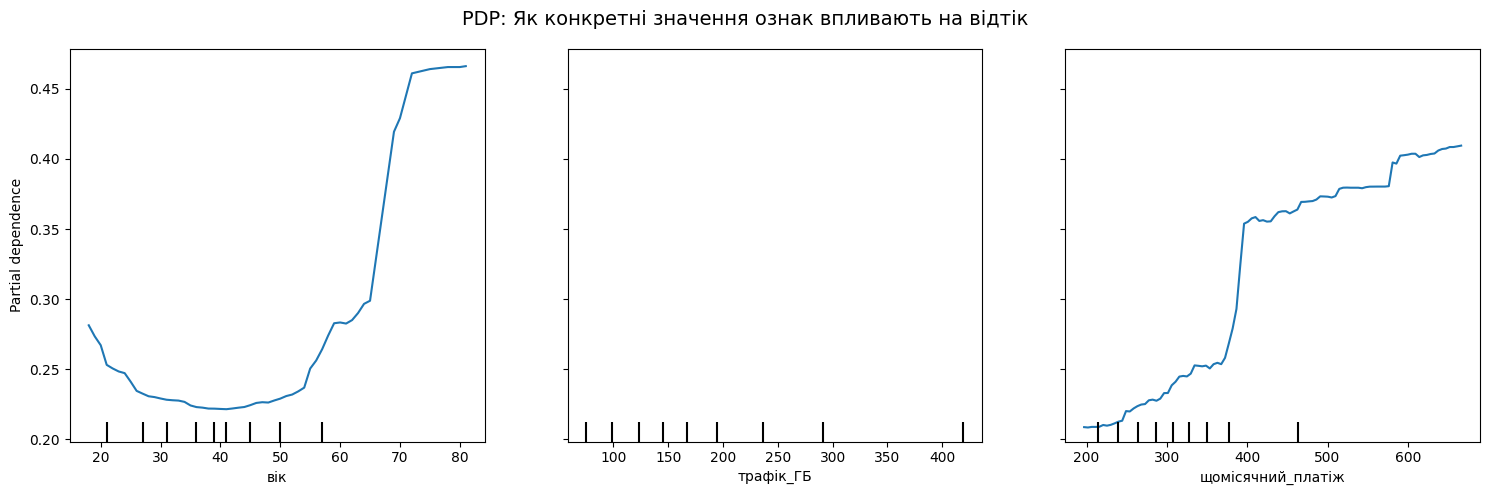

In [37]:
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

top_features = ['вік', 'трафік_ГБ', 'щомісячний_платіж']

fig, ax = plt.subplots(figsize=(15, 5))
PartialDependenceDisplay.from_estimator(
    model,       # твоя фінальна навчена модель
    Xte,         # тестова вибірка
    features=top_features,
    ax=ax
)
plt.suptitle('PDP: Як конкретні значення ознак впливають на відтік', fontsize=14)
plt.tight_layout()
plt.show()

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

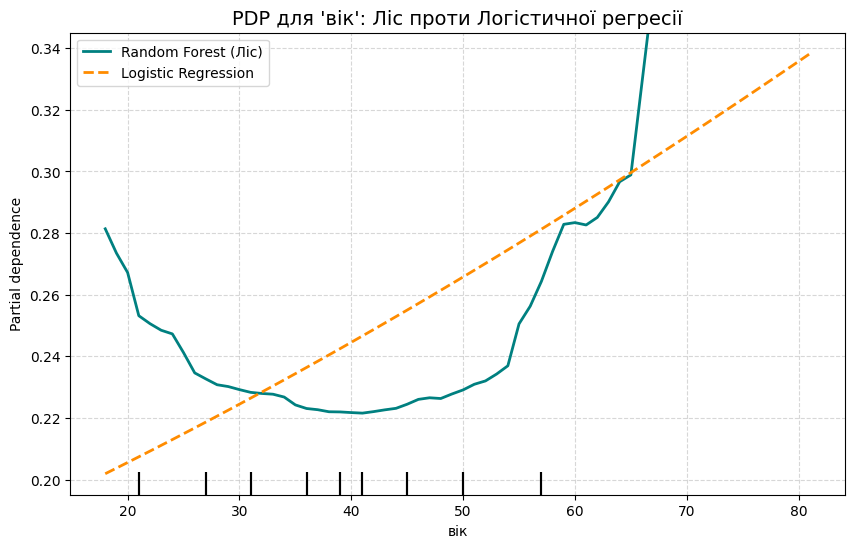

In [38]:
from sklearn.inspection import PartialDependenceDisplay
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt

NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

lr_model = make_pipe(FINAL_X, LogisticRegression(max_iter=1000, random_state=SEED)).fit(Xtr, ytr)

fig, ax = plt.subplots(figsize=(10, 6))

disp = PartialDependenceDisplay.from_estimator(
    model, Xte, features=[NONLINEAR_FEATURE], ax=ax, 
    line_kw={'label': 'Random Forest (Ліс)', 'color': 'teal', 'linewidth': 2}
)

PartialDependenceDisplay.from_estimator(
    lr_model, Xte, features=[NONLINEAR_FEATURE], ax=disp.axes_, 
    line_kw={'label': 'Logistic Regression', 'color': 'darkorange', 'linewidth': 2, 'linestyle': '--'}
)

plt.title(f"PDP для '{NONLINEAR_FEATURE}': Ліс проти Логістичної регресії", fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [39]:
NONLINEAR_MEANING = 'Клієнти середнього віку найбільш лояльні, молоодь та старі частіше йдуть, тому логістична регресія не може в повній мірі описати часткову залежність.'

NONLINEAR_FIX = 'Потрібно розбити вік на діапазони та зробити One-Hot Encoding, тоді для кожної категорії буде точніше описано часткову залежнність'

assert NONLINEAR_MEANING and NONLINEAR_FIX
print("ЗМІСТОВНО:")
print(NONLINEAR_MEANING)
print("\nРІШЕННЯ ДЛЯ ЛІНІЙНОЇ МОДЕЛІ:")
print(NONLINEAR_FIX)

ЗМІСТОВНО:
Клієнти середнього віку найбільш лояльні, молоодь та старі частіше йдуть, тому логістична регресія не може в повній мірі описати часткову залежність.

РІШЕННЯ ДЛЯ ЛІНІЙНОЇ МОДЕЛІ:
Потрібно розбити вік на діапазони та зробити One-Hot Encoding, тоді для кожної категорії буде точніше описано часткову залежнність


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
from sklearn.inspection import partial_dependence
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
import numpy as np

pdp_results = partial_dependence(model, Xte, features=['вік'])

ages = pdp_results['grid_values'][0]       # Всі точки осі X (вік)
pdp_values = pdp_results['average'][0] # Всі точки осі Y (ризик відтоку)

min_idx = np.argmin(pdp_values)
OPTIMAL_AGE = ages[min_idx]

print(f"Програмно знайдений оптимальний вік (дно ковша): {OPTIMAL_AGE}")

FINAL_X_new = FINAL_X.copy()

FINAL_X_new['вік_відхилення_кв'] = (FINAL_X_new['вік'] - OPTIMAL_AGE) ** 2

Xtr_new, Xte_new, ytr_new, yte_new = train_test_split(
    FINAL_X_new, y, test_size=0.3, stratify=y, random_state=SEED
)

lr_base = make_pipe(FINAL_X, LogisticRegression(max_iter=1000, random_state=SEED)).fit(Xtr, ytr)
probs_base = lr_base.predict_proba(Xte)[:, 1]
auc_base = roc_auc_score(yte, probs_base)

lr_enhanced = make_pipe(FINAL_X_new, LogisticRegression(max_iter=1000, random_state=SEED)).fit(Xtr_new, ytr_new)
probs_enhanced = lr_enhanced.predict_proba(Xte_new)[:, 1]
auc_enhanced = roc_auc_score(yte_new, probs_enhanced)

print(f"ROC-AUC базової логістичної регресії:    {auc_base:.5f}")
print(f"ROC-AUC регресії з нелінійною ознакою:   {auc_enhanced:.5f}")
print(f"Приріст якості (ROC-AUC):                {auc_enhanced - auc_base:+.5f}")

Програмно знайдений оптимальний вік (дно ковша): 41.0
ROC-AUC базової логістичної регресії:    0.80539
ROC-AUC регресії з нелінійною ознакою:   0.82395
Приріст якості (ROC-AUC):                +0.01856


In [41]:
QUAD_GAIN = 0.01856
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0186


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

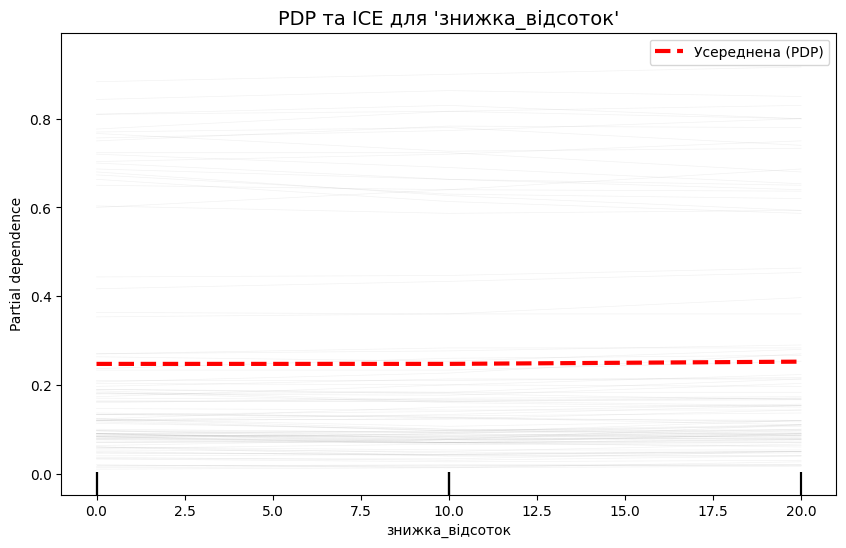

In [42]:
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

# ----- ВАШ КОД: пункт 1 і 2, PDP та ICE для 'знижка_відсоток' -----
fig, ax = plt.subplots(figsize=(10, 6))

PartialDependenceDisplay.from_estimator(
    model, 
    FINAL_X, 
    features=['знижка_відсоток'], 
    kind='both', 
    subsample=100, 
    ax=ax,
    line_kw={'color': 'red', 'linewidth': 3, 'label': 'Усереднена (PDP)'},
    ice_lines_kw={'color': 'gray', 'alpha': 0.1, 'linewidth': 0.5}
)
plt.title("PDP та ICE для 'знижка_відсоток'", fontsize=14)
plt.legend()
plt.show()

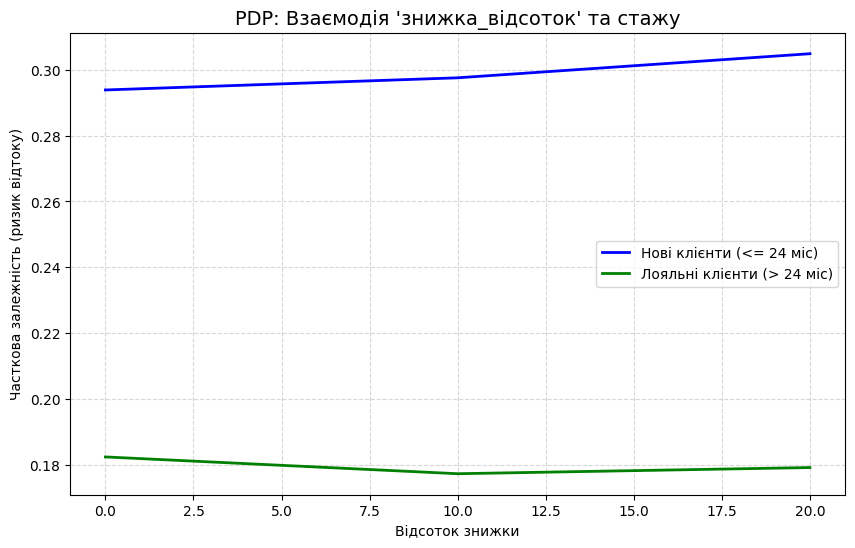

In [43]:
from sklearn.inspection import partial_dependence

TENURE_COL = 'місяців_обслуговування' 

mask_new = FINAL_X[TENURE_COL] <= 24
mask_old = FINAL_X[TENURE_COL] > 24

pdp_new = partial_dependence(model, FINAL_X[mask_new], features=['знижка_відсоток'], kind='average')
pdp_old = partial_dependence(model, FINAL_X[mask_old], features=['знижка_відсоток'], kind='average')

grid_key = 'grid_values'
x_val = pdp_new[grid_key][0] 

y_new = pdp_new['average'][0]
y_old = pdp_old['average'][0]

plt.figure(figsize=(10, 6))
plt.plot(x_val, y_new, label='Нові клієнти (<= 24 міс)', color='blue', linewidth=2)
plt.plot(x_val, y_old, label='Лояльні клієнти (> 24 міс)', color='green', linewidth=2)

plt.title("PDP: Взаємодія 'знижка_відсоток' та стажу", fontsize=14)
plt.xlabel('Відсоток знижки')
plt.ylabel('Часткова залежність (ризик відтоку)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
import pandas as pd
import numpy as np

df_raw = FINAL_X.copy()
df_raw['відтік_факт'] = y 

TENURE_COL = 'місяців_обслуговування'

df_raw['група_стажу'] = np.where(df_raw[TENURE_COL] <= 24, '1. Нові (<= 24 міс)', '2. Лояльні (> 24 міс)')

empirical_stat = df_raw.groupby(['група_стажу', 'знижка_відсоток'])['відтік_факт'].agg(
    емпірична_частка_відтоку='mean',
    розмір_групи='count'
).round({'емпірична_частка_відтоку': 3}) 

display(empirical_stat)

емпірична_частка_відтоку  розмір_групи
група_стажу           знижка_відсоток                                        
1. Нові (<= 24 міс)   0.0                                 0.278           273
                      10.0                                0.314           226
                      20.0                                0.370           200
2. Лояльні (> 24 міс) 0.0                                 0.215           191
                      10.0                                0.148           169
                      20.0                                0.085           141

In [45]:
INTERACTION_FOUND = 'Знижка по-різному впливає на клієнтів залежно від стажу. Для нових клієнтів (до 24 місяців) велика знижка лише збільшує ймовірність відтоку, приваблюючи нелояльних клієнтів, які після закінчення акції не будуть користуватись послугами. Натомість для лояльних клієнтів знижка працює ефективно і суттєво знижує ризик відтоку.'

BUSINESS_ACTION = 'Відділу утримання слід припинити масово роздавати великі знижки новим клієнтам — це марнотратство, яке не гарантує лояльності. Маркетинговий бюджет варто сфокусувати на клієнтах зі стажем понад 2 роки: для них персональні знижки працюють як реальний стимул залишитися в компанії.'

assert INTERACTION_FOUND and BUSINESS_ACTION
print("ЩО ЗНАЙДЕНО (ВЗАЄМОДІЯ):")
print(INTERACTION_FOUND)
print("\nБІЗНЕС-ДІЯ (РІШЕННЯ):")
print(BUSINESS_ACTION)

ЩО ЗНАЙДЕНО (ВЗАЄМОДІЯ):
Знижка по-різному впливає на клієнтів залежно від стажу. Для нових клієнтів (до 24 місяців) велика знижка лише збільшує ймовірність відтоку, приваблюючи нелояльних клієнтів, які після закінчення акції не будуть користуватись послугами. Натомість для лояльних клієнтів знижка працює ефективно і суттєво знижує ризик відтоку.

БІЗНЕС-ДІЯ (РІШЕННЯ):
Відділу утримання слід припинити масово роздавати великі знижки новим клієнтам — це марнотратство, яке не гарантує лояльності. Маркетинговий бюджет варто сфокусувати на клієнтах зі стажем понад 2 роки: для них персональні знижки працюють як реальний стимул залишитися в компанії.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])     
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 78)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

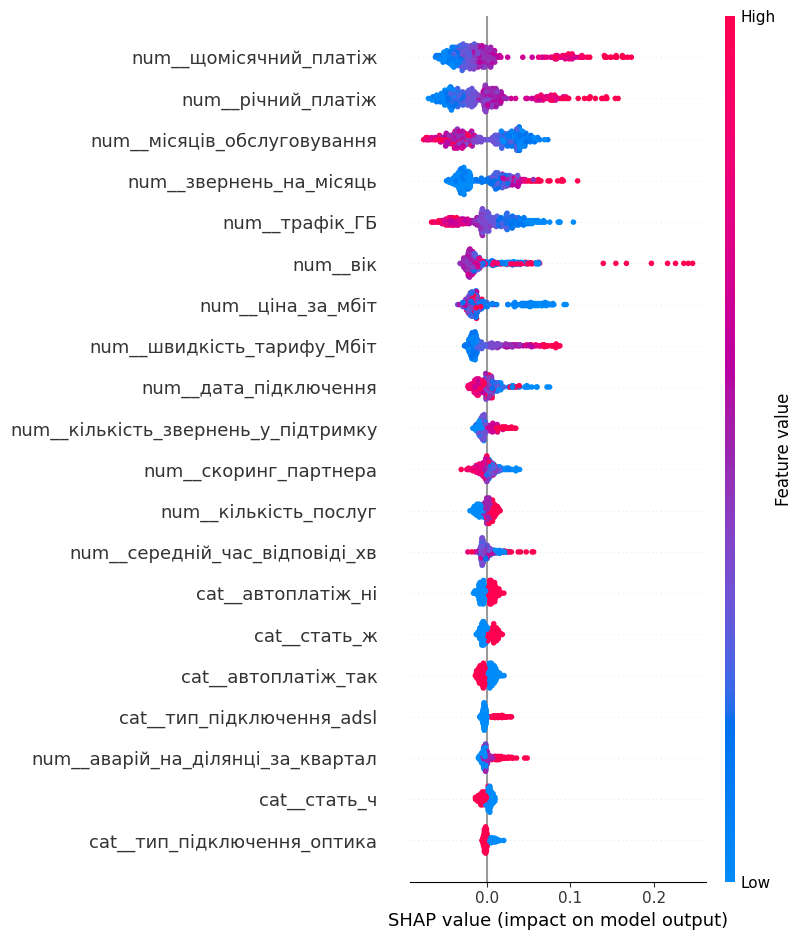

In [47]:
import shap
import pandas as pd

clf = model.named_steps['clf']

if 'prep' in model.named_steps:
    prep = model.named_steps['prep']
    Xte_prep_array = prep.transform(Xte)
    
    if hasattr(prep, 'get_feature_names_out'):
        correct_columns = prep.get_feature_names_out()
    else:
        correct_columns = [f"Feature {i}" for i in range(Xte_prep_array.shape[1])]
        
    Xte_prep = pd.DataFrame(Xte_prep_array, columns=correct_columns, index=Xte.index)
else:
    Xte_prep = Xte

explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(Xte_prep)

if isinstance(shap_values, list):
    shap_vals_churn = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_vals_churn = shap_values[:, :, 1]
else:
    shap_vals_churn = shap_values

shap.summary_plot(shap_vals_churn, Xte_prep)

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
import numpy as np


SAMPLE = len(Xte) 

idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
client_risk = model.predict_proba(Xte)[:SAMPLE, 1][idx]
print('Ризик клієнта: %.3f\n' % client_risk)


client_shap = shap_vals_churn[idx]

top_3_indices = np.argsort(np.abs(client_shap))[-3:][::-1]


human_names = {
        'вік': 'Вік',
        'стаж': 'Час перебування з нами (стаж)',
        'знижка': 'Наявна знижка',
        'ціна': 'Ціна тарифу',
        'автоплатіж_так': 'Наявність автоплатежу',
        'автоплатіж_ні': 'Відсутність автоплатежу (ручна оплата)',
        'трафік': 'Обсяг споживання послуг (трафік)',
        'звернень_на_місяць': 'Частота дзвінків у підтримку',
        'швидкість': 'Швидкість тарифного плану'
}

print("--- ПОВІДОМЛЕННЯ ДЛЯ МЕНЕДЖЕРА З УТРИМАННЯ ---")
print(f"Увага! Ймовірність втрати цього клієнта становить {client_risk*100:.1f}%.")
print("Три головні персональні фактори, що формують цю ситуацію:\n")

for i in top_3_indices:
    raw_name = Xte_prep.columns[i]
    shap_val = client_shap[i]
    real_val = Xte_prep.iloc[idx, i]
    
    biz_name = next((v for k, v in human_names.items() if k in raw_name.lower()), 
                    raw_name.replace('num__', '').replace('cat__', '').replace('_', ' ').capitalize())
    
    if shap_val > 0:
        impact = "суттєво погіршує ситуацію і підштовхує до відмови"
    else:
        impact = "працює нам на користь (утримує клієнта)"
        
    print(f"- {biz_name} (масштабоване значення в базі: {real_val:.2f}). Цей фактор {impact}.")

Ризик клієнта: 0.837

--- ПОВІДОМЛЕННЯ ДЛЯ МЕНЕДЖЕРА З УТРИМАННЯ ---
Увага! Ймовірність втрати цього клієнта становить 83.7%.
Три головні персональні фактори, що формують цю ситуацію:

- Щомісячний платіж (масштабоване значення в базі: 3.51). Цей фактор суттєво погіршує ситуацію і підштовхує до відмови.
- Річний платіж (масштабоване значення в базі: 3.42). Цей фактор суттєво погіршує ситуацію і підштовхує до відмови.
- Швидкість тарифного плану (масштабоване значення в базі: 2.67). Цей фактор суттєво погіршує ситуацію і підштовхує до відмови.


In [49]:
EXPLANATION_FOR_MANAGER = (
    "Ризик втрати клієнта становить критичні 84%. "
    "Основні причини відтоку: зависока сума щомісячного рахунку, відповідно висока сума річного(можливо відсутність автоплатежу) та недостатня швидкість інтернету. "
    "Для утримання рекомендуємо терміново запропонувати клієнту вигідніший швидкісний тариф і допомогти налаштувати автоматичну оплату."
)

assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Ризик втрати клієнта становить критичні 84%. Основні причини відтоку: зависока сума щомісячного рахунку, відповідно висока сума річного(можливо відсутність автоплатежу) та недостатня швидкість інтернету. Для утримання рекомендуємо терміново запропонувати клієнту вигідніший швидкісний тариф і допомогти налаштувати автоматичну оплату.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE = 'звернень_на_місяць'
SHAP_NOT_CAUSAL_WHY = 'якщо ми штучно змінимо значення звернень на місяцб, це нічого не дасть, бо звернення - це наслідок проблеми незадоволення. Модель користується цією ознакою, проте якщо ми наприклад просто заберемо цю ознаку, проблема залишиться, ми просто втратимо одну ознаку з якою можна точніше визначати шанс відтоку'
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

звернень_на_місяць — якщо ми штучно змінимо значення звернень на місяцб, це нічого не дасть, бо звернення - це наслідок проблеми незадоволення. Модель користується цією ознакою, проте якщо ми наприклад просто заберемо цю ознаку, проблема залишиться, ми просто втратимо одну ознаку з якою можна точніше визначати шанс відтоку


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",щомісячний_платіж + річний_платіж,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",звернень_на_місяць,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:

call_cols = [col for col in Xte.columns if 'звернень' in col.lower()]
print("\n--- КОРЕЛЯЦІЯ ЗВЕРНЕНЬ ---")
print(Xte[call_cols].corr())


--- КОРЕЛЯЦІЯ ЗВЕРНЕНЬ ---
                                кількість_звернень_у_підтримку  звернень_на_місяць
кількість_звернень_у_підтримку                        1.000000            0.513447
звернень_на_місяць                                    0.513447            1.000000


In [53]:
FIFTH_MISTAKE = 'можна неправильно проаналізувати і подумати, що кількість звернень у підтримку та звернень на місяць - це сильно корелюючі ознаки, тому одну з них можна видалити. хоча вони й показують схожі результати, проте вони обоє важливі, і при видаленні одної з них ми втртимо важливу ознаку'
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

можна неправильно проаналізувати і подумати, що кількість звернень у підтримку та звернень на місяць - це сильно корелюючі ознаки, тому одну з них можна видалити. хоча вони й показують схожі результати, проте вони обоє важливі, і при видаленні одної з них ми втртимо важливу ознаку


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [54]:
import numpy as np

TOP_N = 100

probs = model.predict_proba(Xte)[:, 1]

top_100_idx = np.argsort(probs)[-TOP_N:]

if hasattr(yte, 'iloc'): # якщо це pandas Series
    actuals_top = yte.iloc[top_100_idx]
else:                    # якщо це numpy масив
    actuals_top = yte[top_100_idx]

churn_rate_top = actuals_top.mean()
churn_rate_all = yte.mean()

lift = churn_rate_top / churn_rate_all

print(f"Частка відтоку в усій базі: {churn_rate_all:.3f}")
print(f"Частка відтоку в топ-{TOP_N}: {churn_rate_top:.3f}")
print(f"Метрика Lift: {lift:.2f}")

Частка відтоку в усій базі: 0.250
Частка відтоку в топ-100: 0.550
Метрика Lift: 2.20


In [55]:
LIFT_MEANING = (
    "Показник Lift = 2.2 означає, що наша модель у 2.2 раза ефективніша за випадкове вгадування.тому замість того, щоб дзвонити рандомним людям, зважаючи шо в нас обмеження 100 людей, ми можемо відсортувати всіх людей і знайти 100 найризикованіших, і це буде ефективніше в 2.2 рази."
)

assert LIFT_MEANING
print(LIFT_MEANING)

Показник Lift = 2.2 означає, що наша модель у 2.2 раза ефективніша за випадкове вгадування.тому замість того, щоб дзвонити рандомним людям, зважаючи шо в нас обмеження 100 людей, ми можемо відсортувати всіх людей і знайти 100 найризикованіших, і це буде ефективніше в 2.2 рази.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [56]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_12.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [57]:
REPORT = '''
1. AUC(У вибірці присутній відчутний дисбаланс класів(частка відтоку 0.25), тому інші метрики не дуже підходять, до того ж AUC зручний, бо не потрібно обирати поріг, а він ранжує ризики відтоку
2. Викинуто id_клієнта (з'являється при реєстрації, просто технічний ID), дата_розірвання та сума_повернення_депозиту (з'являються в майбутньому вже після розірвання договору), оцінка_ризику_менеджером (ставиться менеджером під час або після самої розмови) та філія (фіксується при підключенні, але є артефактом збору). Детектор із 5.1 не знайшов оцінка_ризику_менеджером, бо він шукає витік лише через наявність пропусків (NaN), а ця колонка заповнена у всіх 100% клієнтів.
3. Чесне число якості становить AUC = 0,785 ± 0,039 (а при парному порівнянні на фолдах похибка різниці складає близько ± 0,015). Такий розкид означає, що різниця між моделями у 0,004 повністю лежить у межах випадкового статистичного шуму, тому вважати одну модель кращою за іншу не можна.
4. Так, є артефакт збору за ознакою філія (у Ф-01 та Ф-02 відтік ~40% проти ~16–20% в інших), і модель на чесних ознаках вгадує це джерело з AUC = 0,714. Оскільки ознаки клієнтів системно відрізняються між філіями, цій моделі не можна сліпо довіряти в іншій філії без додаткової перевірки та перекалібрування.
5. Формально більше дала складніша модель — гістограмний бустинг показав приріст +0,0068 ± 0,0150 за 15,1 с (випадковий ліс -0,0002 ± 0,0148 за 7,9 с проти 1,4 с у регресії), але це в межах шуму. Нові ознаки на логістичній регресії через колінеарність дали -0,0027 ± 0,0014 (час ~1,4 с).
6. Вбудована важливість помилково назвала найважливішою ознаку код_тарифного_плану (1-ше місце з показником 0,1001, тоді як перестановочна важливість дорівнює -0,0001). Дерева так роблять, бо ця ознака має багато унікальних значень (40 категорій), що дає дереву купу варіантів для розбиття, якими воно просто перенавчається під шум тренувальної вибірки.
7. У повній моделі дубльована пара щомісячний_платіж та річний_платіж (r = 0,9992) розділила важливість між собою (+0,0195 та +0,0137), а після вилучення річний_платіж важливість щомісячний_платіж зросла до +0,0261. Це не вада методу, бо при перемішуванні лише однієї колонки модель чесно бере ту саму інформацію з її дубліката, тому якість прогнозу майже не падає.   
8. Немонотонний вплив має вік — ризик відтоку високий у молоді, падає до мінімуму в 35–50 років і знову стрімко зростає після 55 років. Логістична регресія цього не побачить, бо за своєю природою може побудувати лише монотонну залежність.
9. PDP збрехав через усереднення там, де є взаємодія ознак, показавши занадто плавну середню криву, оскільки протилежні реакції різних груп клієнтів взаємно погасили одна одну. Натомість ICE показав індивідуальні лінії для кожного клієнта окремо, де видно, що в одних абонентів ризик різко стрибає на десятки відсотків, а в інших залишається плоским.
10. Прикладом є звернень_на_місяць: якщо штучно заблокувати клієнту прийом скарг у підтримку, ризик його відтоку не зменшиться. 
11. За допомогою моделі ми отримаємо Lift 2,2, тобто серед 100 обдзвонених виявимо у 2,2 раза більше реальних клієнтів із групи ризику. Застереження: близько 40% клієнтів у цьому списку все одно будуть хибнопозитивними (вони не збиралися йти), тому пропонувати знижку всім підряд невигідно, а тим, хто йде через погану якість інтернету, знижка не допоможе.

Декларація про використання ШІ: Gemini, допомога з усім кодом та логікою, незначна допомога з текстом
'''
print(REPORT)


1. AUC(У вибірці присутній відчутний дисбаланс класів(частка відтоку 0.25), тому інші метрики не дуже підходять, до того ж AUC зручний, бо не потрібно обирати поріг, а він ранжує ризики відтоку
2. Викинуто id_клієнта (з'являється при реєстрації, просто технічний ID), дата_розірвання та сума_повернення_депозиту (з'являються в майбутньому вже після розірвання договору), оцінка_ризику_менеджером (ставиться менеджером під час або після самої розмови) та філія (фіксується при підключенні, але є артефактом збору). Детектор із 5.1 не знайшов оцінка_ризику_менеджером, бо він шукає витік лише через наявність пропусків (NaN), а ця колонка заповнена у всіх 100% клієнтів.
3. Чесне число якості становить AUC = 0,785 ± 0,039 (а при парному порівнянні на фолдах похибка різниці складає близько ± 0,015). Такий розкид означає, що різниця між моделями у 0,004 повністю лежить у межах випадкового статистичного шуму, тому вважати одну модель кращою за іншу не можна.
4. Так, є артефакт збору за ознакою філі

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.